# Терең оқыту әдістері негізінде жалған жаңалықтарды анықтау жүйесін әзірлеу
### Разработка системы обнаружения фейковых новостей на основе глубокого обучения
Курсовая работа по дисциплине «Глубокое обучение». Студент: Жарқымбай Заңғар Берікұлы, группа ЖИТ-33.

**Идея простыми словами:** даём компьютеру тысячи новостей, про каждую известно, правдивая она (REAL) или фейк (FAKE). Нейросеть сама находит закономерности в словах и потом угадывает, фейк ли новая новость.

**План:**
1. Загрузить и посмотреть данные
2. Подготовить текст (очистить, превратить слова в числа)
3. Простая модель для сравнения (TF-IDF + логистическая регрессия)
4. Нейросеть глубокого обучения: BiLSTM
5. Сравнить результаты и проверить на своей новости

## 1. Подключаем библиотеки
`pandas` для таблиц, `torch` (PyTorch) для нейросети, `sklearn` для метрик и простой модели, `matplotlib` для графиков.

In [1]:
import re, random, collections
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42  # фиксируем случайность, чтобы результаты повторялись
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Устройство:', device)

Устройство: cpu


## 2. Загружаем датасет
Датасет **Fake or Real News** (6335 англоязычных новостей, около половины фейков). Столбцы: `title` заголовок, `text` текст, `label` метка FAKE или REAL.

In [2]:
URL = 'https://raw.githubusercontent.com/lutzhamel/fake-news/master/data/fake_or_real_news.csv'
df = pd.read_csv(URL)
df = df.dropna(subset=['text'])
df['content'] = df['title'].fillna('') + ' ' + df['text']   # заголовок + текст вместе
df['y'] = (df['label'] == 'FAKE').astype(int)                # 1 = фейк, 0 = правда
print('Размер:', df.shape)
print(df['label'].value_counts())
df[['title','label']].head()

Размер: (6335, 6)
label
REAL    3171
FAKE    3164
Name: count, dtype: int64


,title,label
0,You Can Smell Hillary’s Fear,FAKE
1,Watch The Exact Moment Paul Ryan Committed Pol...,FAKE
2,Kerry to go to Paris in gesture of sympathy,REAL
3,Bernie supporters on Twitter erupt in anger ag...,FAKE
4,The Battle of New York: Why This Primary Matters,REAL


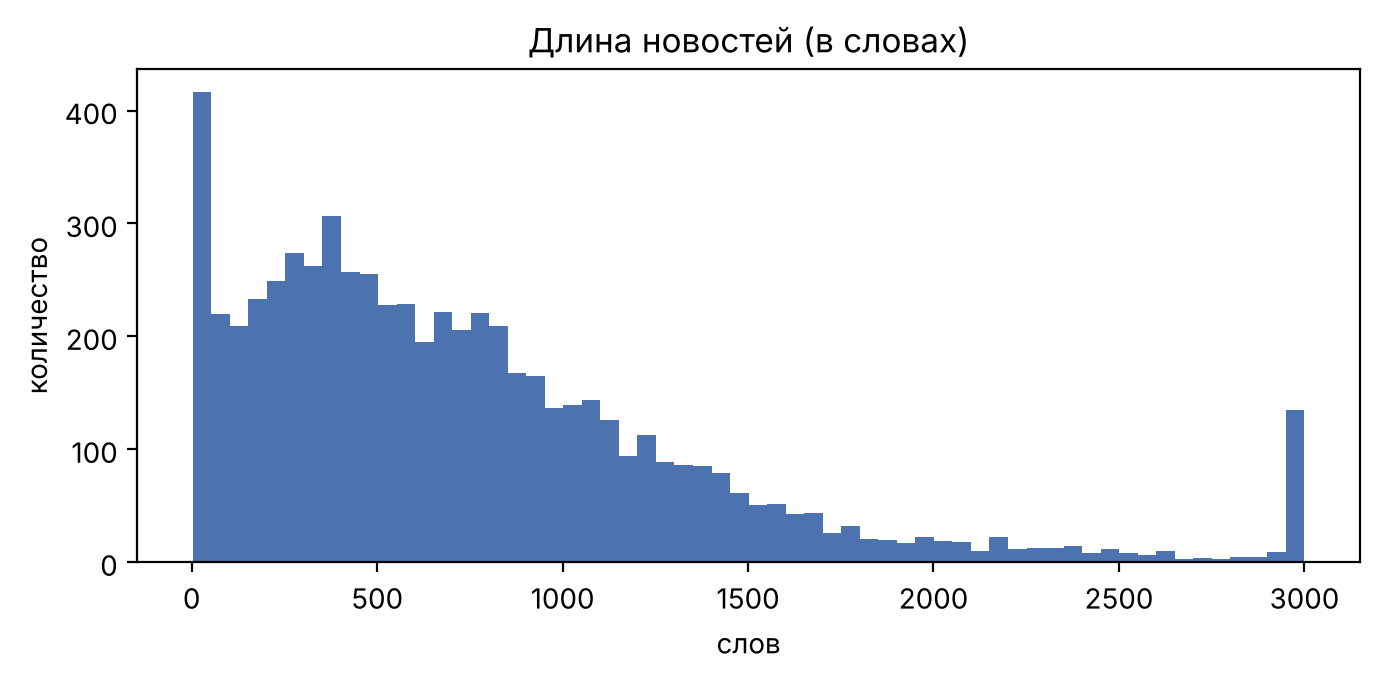

Медиана длины: 608 слов


In [3]:
lens = df['content'].str.split().str.len()
plt.figure(figsize=(7,3.5))
plt.hist(lens.clip(upper=3000), bins=60, color='#4C72B0')
plt.title('Длина новостей (в словах)'); plt.xlabel('слов'); plt.ylabel('количество')
plt.tight_layout(); plt.savefig('fig_lengths.png', dpi=150); plt.show()
print('Медиана длины:', int(lens.median()), 'слов')

## 3. Очистка текста и разделение данных
Приводим к маленьким буквам, убираем ссылки и лишние символы. Делим данные: **70% обучение**, **15% валидация** (подбор), **15% тест** (честная финальная проверка, модель их не видит при обучении).

In [4]:
def clean(t):
    t = t.lower()
    t = re.sub(r'http\S+|www\.\S+', ' ', t)
    t = re.sub(r"[^a-z0-9' ]", ' ', t)
    return re.sub(r'\s+', ' ', t).strip()

df['clean'] = df['content'].map(clean)
X_train, X_tmp, y_train, y_tmp = train_test_split(df['clean'], df['y'], test_size=0.30, random_state=SEED, stratify=df['y'])
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=SEED, stratify=y_tmp)
print(len(X_train), len(X_val), len(X_test))

4434 950 951


## 4. Простая модель для сравнения (baseline)
**TF-IDF** считает, насколько каждое слово важно для текста. **Логистическая регрессия** это простой классический алгоритм. Нужна, чтобы понять, лучше ли нейросеть.

In [5]:
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1,2), stop_words='english')
Xtr = tfidf.fit_transform(X_train); Xte = tfidf.transform(X_test)
logreg = LogisticRegression(max_iter=1000).fit(Xtr, y_train)
pred_lr = logreg.predict(Xte)

def report(name, y_true, y_pred):
    r = dict(Модель=name, Accuracy=accuracy_score(y_true,y_pred), Precision=precision_score(y_true,y_pred),
             Recall=recall_score(y_true,y_pred), F1=f1_score(y_true,y_pred))
    print({k:(round(v,4) if isinstance(v,float) else v) for k,v in r.items()}); return r
res_lr = report('TF-IDF + LogReg', y_test, pred_lr)

{'Модель': 'TF-IDF + LogReg', 'Accuracy': 0.9117, 'Precision': 0.8949, 'Recall': 0.9326, 'F1': 0.9134}


## 5. Подготовка текста для нейросети
Нейросеть понимает только числа. Строим **словарь** из 20 000 самых частых слов, каждое слово получает номер. Каждую новость обрезаем или дополняем нулями до **400 слов**.

In [6]:
MAX_WORDS, MAX_LEN = 20000, 400
counter = collections.Counter(w for t in X_train for w in t.split())
vocab = {w:i+2 for i,(w,_) in enumerate(counter.most_common(MAX_WORDS-2))}   # 0 = пусто, 1 = неизвестное слово

def encode(t):
    ids = [vocab.get(w,1) for w in t.split()][:MAX_LEN]
    return ids + [0]*(MAX_LEN-len(ids))

def make_loader(X, y, shuffle):
    xs = torch.tensor([encode(t) for t in X]); ys = torch.tensor(y.values, dtype=torch.float32)
    return DataLoader(TensorDataset(xs, ys), batch_size=64, shuffle=shuffle)

train_dl, val_dl, test_dl = make_loader(X_train,y_train,True), make_loader(X_val,y_val,False), make_loader(X_test,y_test,False)
print('Пример закодированной новости:', encode(X_train.iloc[0])[:15], '...')

Пример закодированной новости: [49, 4481, 40, 3506, 1, 144, 40, 886, 4, 459, 1152, 49, 4481, 40, 3506] ...


## 6. Модель BiLSTM
- **Embedding**: превращает номер слова в вектор из 128 чисел (смысл слова).
- **BiLSTM**: рекуррентная сеть, читает текст слева направо и справа налево и запоминает контекст.
- **Dropout**: случайно отключает часть нейронов, чтобы модель не зубрила (защита от переобучения).
- **Linear + Sigmoid**: выдаёт вероятность, что новость фейк (от 0 до 1).

In [7]:
class BiLSTM(nn.Module):
    def __init__(self, vocab_size=MAX_WORDS, emb=128, hidden=64):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=0)
        self.lstm = nn.LSTM(emb, hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(0.4)
        self.fc = nn.Linear(hidden*2, 1)
    def forward(self, x):
        h, _ = self.lstm(self.emb(x))                 # (batch, len, 2*hidden)
        mask = (x != 0).unsqueeze(-1).float()
        h = (h*mask).sum(1) / mask.sum(1).clamp(min=1)  # среднее по словам
        return self.fc(self.drop(h)).squeeze(-1)        # логит

model = BiLSTM().to(device)
print(model)
print('Параметров:', sum(p.numel() for p in model.parameters()))

BiLSTM(
  (emb): Embedding(20000, 128, padding_idx=0)
  (lstm): LSTM(128, 64, batch_first=True, bidirectional=True)
  (drop): Dropout(p=0.4, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)
Параметров: 2659457


## 7. Обучение
**Эпоха** это один проход по всем обучающим новостям. Функция потерь `BCEWithLogitsLoss` показывает, насколько модель ошибается; оптимизатор **Adam** понемногу исправляет веса. Сохраняем лучшую по валидации версию.

In [8]:
loss_fn = nn.BCEWithLogitsLoss(); opt = torch.optim.Adam(model.parameters(), lr=1e-3)

def evaluate(dl):
    model.eval(); P, Y, L = [], [], 0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device); out = model(xb)
            L += loss_fn(out, yb).item()*len(yb); P += (torch.sigmoid(out)>0.5).int().tolist(); Y += yb.int().tolist()
    return L/len(Y), accuracy_score(Y,P), P

hist = dict(train_loss=[], val_loss=[], train_acc=[], val_acc=[]); best = 0
for epoch in range(1, 9):
    model.train()
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    tl, ta, _ = evaluate(train_dl); vl, va, _ = evaluate(val_dl)
    for k,v in zip(hist, (tl,vl,ta,va)): hist[k].append(v)
    if va > best: best = va; torch.save(model.state_dict(), 'best_bilstm.pt')
    print(f'Эпоха {epoch}: loss {tl:.3f}/{vl:.3f}  accuracy {ta:.3f}/{va:.3f}  (обучение/валидация)')

Эпоха 1: loss 0.437/0.443  accuracy 0.804/0.811  (обучение/валидация)


Эпоха 2: loss 0.382/0.402  accuracy 0.851/0.843  (обучение/валидация)


Эпоха 3: loss 0.223/0.313  accuracy 0.915/0.849  (обучение/валидация)


Эпоха 4: loss 0.168/0.299  accuracy 0.939/0.881  (обучение/валидация)


Эпоха 5: loss 0.125/0.307  accuracy 0.951/0.868  (обучение/валидация)


Эпоха 6: loss 0.091/0.313  accuracy 0.966/0.874  (обучение/валидация)


Эпоха 7: loss 0.068/0.275  accuracy 0.980/0.887  (обучение/валидация)


Эпоха 8: loss 0.052/0.297  accuracy 0.984/0.902  (обучение/валидация)


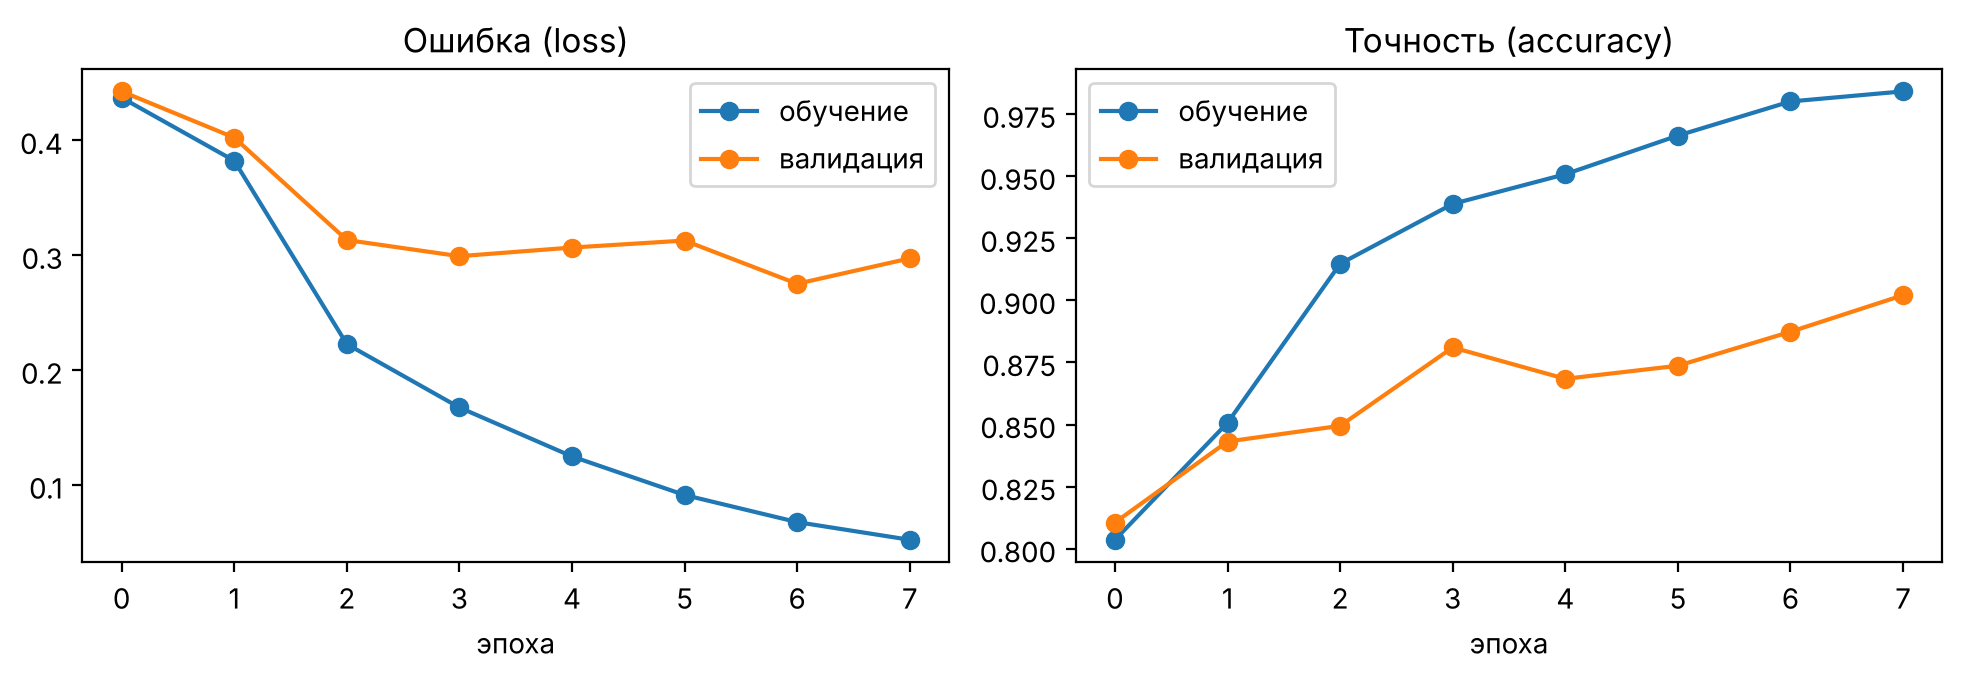

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10,3.5))
ax[0].plot(hist['train_loss'], 'o-', label='обучение'); ax[0].plot(hist['val_loss'], 'o-', label='валидация'); ax[0].set_title('Ошибка (loss)')
ax[1].plot(hist['train_acc'], 'o-', label='обучение'); ax[1].plot(hist['val_acc'], 'o-', label='валидация'); ax[1].set_title('Точность (accuracy)')
for a in ax: a.set_xlabel('эпоха'); a.legend()
plt.tight_layout(); plt.savefig('fig_training.png', dpi=150); plt.show()

## 8. Финальная проверка на тестовых данных
Берём лучшую модель и проверяем на новостях, которых она никогда не видела.

{'Модель': 'BiLSTM', 'Accuracy': 0.8875, 'Precision': 0.8866, 'Recall': 0.8884, 'F1': 0.8875}


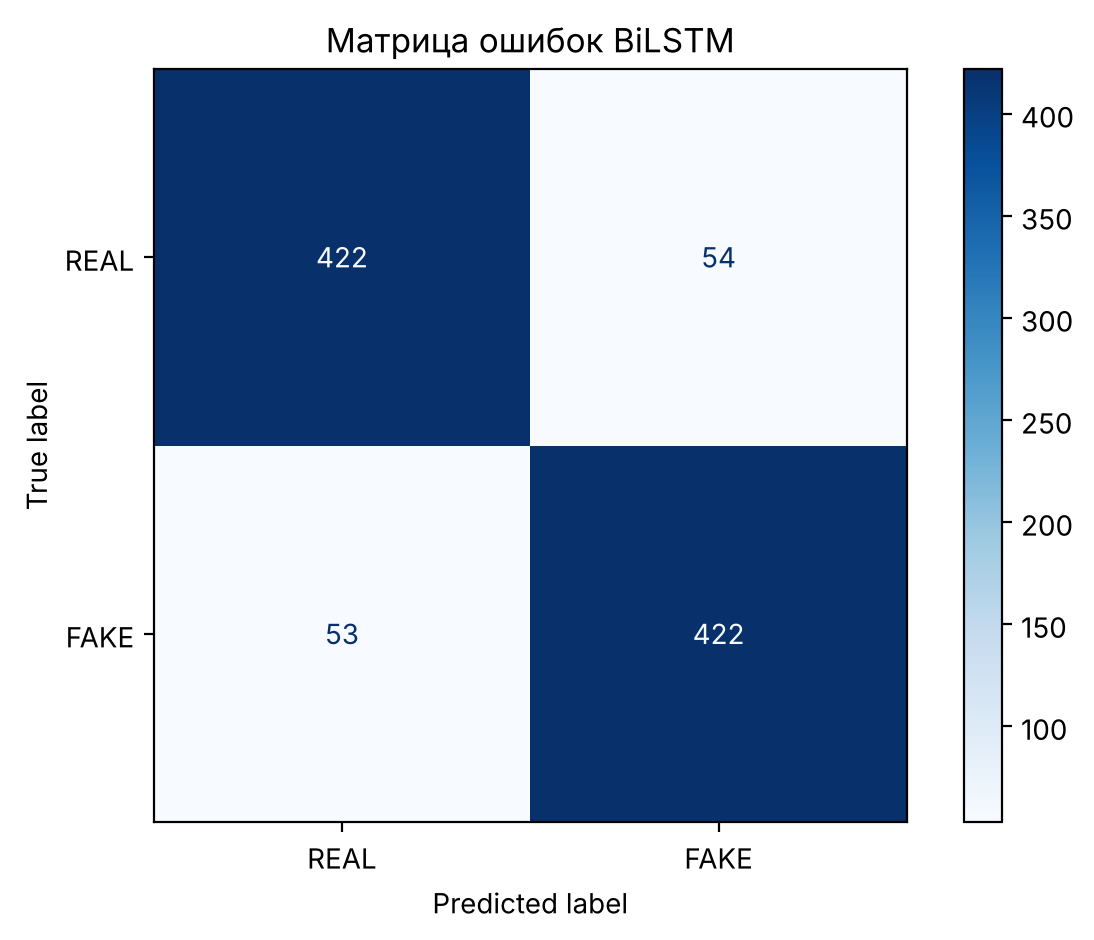

,Accuracy,Precision,Recall,F1
Модель,,,,
TF-IDF + LogReg,0.9117,0.8949,0.9326,0.9134
BiLSTM,0.8875,0.8866,0.8884,0.8875


In [10]:
model.load_state_dict(torch.load('best_bilstm.pt'))
_, _, pred_lstm = evaluate(test_dl)
res_lstm = report('BiLSTM', y_test, pred_lstm)

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_lstm), display_labels=['REAL','FAKE']).plot(cmap='Blues')
plt.title('Матрица ошибок BiLSTM'); plt.tight_layout(); plt.savefig('fig_confusion.png', dpi=150); plt.show()

table = pd.DataFrame([res_lr, res_lstm]).set_index('Модель').round(4)
table.to_csv('results.csv'); table

## 9. Проверка на своей новости
Вставь любой английский текст новости и посмотри, что скажет модель.

In [11]:
def predict(text):
    model.eval()
    x = torch.tensor([encode(clean(text))]).to(device)
    p = torch.sigmoid(model(x)).item()
    return f'FAKE (фейк) с вероятностью {p:.0%}' if p > 0.5 else f'REAL (правда) с вероятностью {1-p:.0%}'

examples = [X_test.iloc[i] for i in range(3)]
for t, y in zip(examples, y_test.iloc[:3]):
    print('Истина:', 'FAKE' if y else 'REAL', '| Модель:', predict(t), '|', t[:90], '...')

Истина: REAL | Модель: REAL (правда) с вероятностью 100% | john kasich wooing iowans mostly from new hampshire john kasich was killing it with these  ...
Истина: REAL | Модель: REAL (правда) с вероятностью 100% | reuters poll most voters don't think bill clinton big factor in election bill clinton simp ...
Истина: REAL | Модель: REAL (правда) с вероятностью 100% | why nevada was a bad sign for bernie sanders's political revolution it was bad news for be ...


## 10. Выводы
- Построена система обнаружения фейковых новостей на основе BiLSTM.
- Результаты сравнены с классической моделью TF-IDF + логистическая регрессия (таблица выше).
- Ограничения: датасет англоязычный и небольшой (6335 новостей), модель учится на стиле текста, а не проверяет факты.
- Дальнейшее развитие: трансформеры (BERT), датасет на казахском и русском языках, веб-интерфейс.